# 04 · Logistic Regression (handbook 3.5.2)
Multinomial logistic regression; grid search over C. Each full fit takes minutes, so C is tuned
on a stratified 30k sample of the training set, then the final model is fitted on the full training set.

In [2]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

train (114844, 1711) | val (28712, 1711) | test (35890, 1711)


## Grid search over C (loop, as in the tutorial)

In [5]:
xs, ys = stratified_sample(x_train, y_train, 30000)
C = [0.001, 0.01, 0.1, 1, 10]
f1_val = []
for c in C:
    m = LogisticRegression(C=c, max_iter=3000).fit(xs, ys)
    f1_val.append(macro_f1(y_val, m.predict(x_val)))
    print(c, round(f1_val[-1], 4))
c_opt = C[int(np.argmax(f1_val))]
print("Optimal C:", c_opt)

0.001 0.3623
0.01 0.424
0.1 0.4611
1 0.4526
10 0.4453
Optimal C: 0.1


## Same tuning with GridSearchCV (handbook asks to repeat it; 3-fold CV on the sample)

In [6]:
grid = GridSearchCV(LogisticRegression(max_iter=3000), {"C": C}, scoring="f1_macro", cv=3, n_jobs=-1)
grid.fit(xs, ys)
print("GridSearchCV best C:", grid.best_params_["C"])

GridSearchCV best C: 0.1


## Final model: evaluate on test and save

{'model': 'Logistic Regression', 'accuracy': 0.5017, 'macro_F1': 0.4849, 'ordinal_MAE': 0.7503, 'within_one': 0.824, 'EFG_recall': 0.7321, 'AUC_ovr': 0.8745}


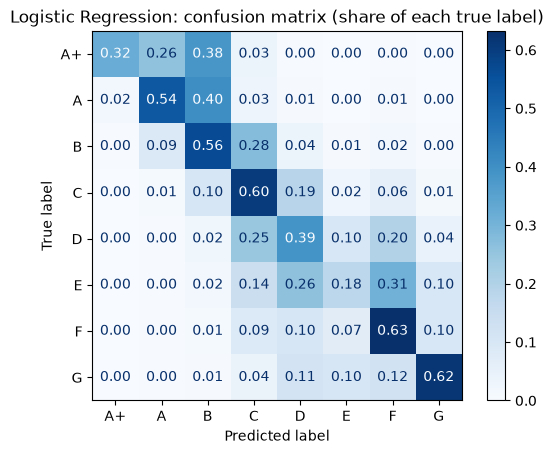

In [7]:
LR = LogisticRegression(C=c_opt, max_iter=2000).fit(x_train, y_train)
evaluate("Logistic Regression", LR, x_test, y_test)
save_model(LR, "LR")

## Most influential features
With 8 classes there is one weight vector (and one bias) per label. Below: the strongest features
for the best (A+) and worst (G) label, and the "does it make sense?" check from the handbook.

In [8]:
coef = pd.DataFrame(LR.coef_, index=LR.classes_, columns=feature_names)
print("Bias per class:")
print(pd.Series(LR.intercept_, index=LR.classes_).reindex(ORDER).round(3))

for cls in ["A+", "G"]:
    top = coef.loc[cls].abs().sort_values(ascending=False).head(8).index
    print(f"\nTop features for class {cls}:")
    print(coef.loc[cls, top].round(3))

Bias per class:
A+   -0.321
A    -0.070
B     0.103
C     0.230
D     0.126
E     0.069
F     0.118
G    -0.255
dtype: float64

Top features for class A+:
num__builtyear                              2.690
cat__solarpanels_no                        -1.298
cat__solarpanels_yes                        1.148
cat__region_Wallonia                        1.119
num__builtyear_is_range                    -0.960
cat__matched_municipality_nis_code_57096    0.882
cat__EPC type_EPC-                         -0.786
cat__region_Brussels                       -0.757
Name: A+, dtype: float64

Top features for class G:
cat__region_Flanders                        -3.364
cat__region_Brussels                         2.517
num__builtyear                              -2.194
cat__building type_terracedHouse            -1.197
cat__regional planning_woongebied           -1.125
cat__regional planning_typisch woongebied    1.110
cat__solarpanels_yes                        -1.063
cat__solarpanels_no                 

In [9]:
feat = coef.loc["G"].abs().idxmax()
col = list(feature_names).index(feat)
vals = x_train[:, col]
vals = vals.toarray().ravel() if hasattr(vals, "toarray") else np.ravel(vals)
print(f"Most influential feature for G: {feat} (weight {coef.loc['G', feat]:.3f})")
print(f"Share of G where {feat} > 0: {np.mean(y_train[vals > 0] == 'G'):.3f}")
print(f"Overall share of G:         {np.mean(y_train == 'G'):.3f}")

Most influential feature for G: cat__region_Flanders (weight -3.364)
Share of G where cat__region_Flanders > 0: 0.000
Overall share of G:         0.066
